## Inference of inclusion diameter and position
### From spike trains to size and location of the hard inclusions

This notebook implements the **second part** of the project. Building on the
spike trains, it infers two physical properties of the hard inclusions embedded in the phantom:

1. **Diameter** of each inclusion (3, 6, 9 or 12 mm), addressed both as a
   **multi-class classification** and as a **regression** problem, to compare
   the two formulations.
2. **Position** of each inclusion, by localizing the centre of every detected
   inclusion on the x-y grid and comparing it with the known geometry.

**Same features as Part 1:** The 19 loading-window features are reused: a
larger sphere produces a steeper, more sustained force during indentation,
hence denser spikes and different temporal patterns. The same rate and timing
features that separated hard from soft should now order with diameter.

**Neuron choice:** One representative file per phantom is used, fixing the
neuron type to the **best-performing neuron of Part 1** (selected on the
*presence* classification).

Libraries for feature extraction, the two diameter formulations (classification and regression), inclusion grouping and the maps.

In [1]:
# ====================================================================
# 0. LIBRARIES
# ====================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

from scipy.stats import skew

from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, KFold

from sklearn.svm import SVC, SVR
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor

from sklearn.model_selection import (
    StratifiedGroupKFold,
    GroupKFold,
    LeaveOneGroupOut,
    cross_val_predict,
)

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    balanced_accuracy_score,
    mean_absolute_error,
    r2_score,
    mutual_info_score,
)

from sklearn.cluster import DBSCAN

RANDOM_STATE = 42

**Feature extraction.** The spike instants are read (as sample indices, converted to seconds) and the same 19 features of Part 1 are computed on the whole spike train, since these files do not store the loading-window markers.

In [2]:
# ====================================================================
# 1. FEATURE EXTRACTION FROM SPIKE TRAINS
# ====================================================================
# The input files store, for every indented point, the spike instants as
# SAMPLE INDICES (one column per spike), together with the metadata columns
# presence, diameter, n_samples, n_spikes, x, y.
#
# These files do not contain contact_start / force_peak, so the features are
# computed on the WHOLE spike train (no loading-window cropping). The feature
# definitions are otherwise identical to Part 1.

# Sampling frequency of the force acquisition, in Hz.
# Spike sample indices are divided by this to obtain spike times in seconds.
SAMPLING_HZ = 1000.0
# Unit conversion to micrometers
UM_TO_MM = 1e-3

META_COLUMNS = ["presence", "diameter", "n_samples", "n_spikes", "x", "y"]


def extractSpikeTimes(row, spike_columns):
    """
    Returns the spike instants of one point, in seconds.

    The spike columns hold sample indices; non-finite entries are padding and
    are discarded. Indices are sorted and divided by the sampling frequency.
    """

    values = pd.to_numeric(
        row[spike_columns],
        errors="coerce"
    ).to_numpy()

    values = values[np.isfinite(values)]
    values = np.sort(values)

    return values / SAMPLING_HZ


def extractFeaturesFromSpikeTimes(spike_times_s, duration_s):
    """
    Computes the 19 candidate features from the spike instants (in seconds).

    The features describe three complementary aspects of the discharge:
    rate / count, ISI statistics, and regularity / shape.
    """

    n_spikes = len(spike_times_s)

    # ----- rate / count -----
    if duration_s > 0:
        firing_rate = n_spikes / duration_s
    else:
        firing_rate = np.nan

    # quartile firing rates over the whole window
    if duration_s > 0:
        edges = np.linspace(0, duration_s, 5)
        counts, _ = np.histogram(spike_times_s, bins=edges)
        quarter = duration_s / 4.0
        fr_q = counts / quarter
        fr_q1, fr_q2, fr_q3, fr_q4 = (float(v) for v in fr_q)

        positions = np.array([0.125, 0.375, 0.625, 0.875])
        if np.all(np.isfinite(fr_q)):
            fr_slope, _ = np.polyfit(positions, fr_q, 1)
            fr_slope = float(fr_slope)
        else:
            fr_slope = np.nan
    else:
        fr_q1 = fr_q2 = fr_q3 = fr_q4 = fr_slope = np.nan

    # ----- ISI statistics -----
    if n_spikes >= 2:
        isi = np.diff(spike_times_s)
        mean_isi = float(np.mean(isi))
        std_isi = float(np.std(isi, ddof=1)) if n_spikes >= 3 else np.nan
        median_isi = float(np.median(isi))
        min_isi = float(np.min(isi))
        max_isi = float(np.max(isi))
        iqr_isi = float(np.percentile(isi, 75) - np.percentile(isi, 25))
        active_span = float(
            (spike_times_s[-1] - spike_times_s[0]) / duration_s
        ) if duration_s > 0 else np.nan
    else:
        mean_isi = std_isi = median_isi = np.nan
        min_isi = max_isi = iqr_isi = active_span = np.nan

    # ----- regularity / shape -----
    if n_spikes >= 3:
        isi = np.diff(spike_times_s)
        mean_isi_v = np.mean(isi)
        cv_isi = float(np.std(isi, ddof=1) / mean_isi_v) if mean_isi_v > 0 else np.nan

        isi_prev = isi[:-1]
        isi_next = isi[1:]
        denom = isi_prev + isi_next
        valid = denom > 0

        if np.any(valid):
            cv2 = float(np.mean(2.0 * np.abs(isi_next[valid] - isi_prev[valid]) / denom[valid]))
            norm_diff = (isi_next[valid] - isi_prev[valid]) / denom[valid]
            lv = float(3.0 * np.mean(norm_diff ** 2))
        else:
            cv2 = lv = np.nan

        isi_skew = float(skew(isi)) if np.std(isi) > 0 else np.nan

        mean_isi_b = np.mean(isi)
        std_isi_b = np.std(isi)
        burstiness = float((std_isi_b - mean_isi_b) / (std_isi_b + mean_isi_b)) \
            if (std_isi_b + mean_isi_b) > 0 else np.nan
    else:
        cv_isi = cv2 = lv = isi_skew = burstiness = np.nan

    return {
        "n_spikes_loading": n_spikes,
        "FR_loading_Hz": firing_rate,
        "FR_Q1_Hz": fr_q1,
        "FR_Q2_Hz": fr_q2,
        "FR_Q3_Hz": fr_q3,
        "FR_Q4_Hz": fr_q4,
        "FR_slope": fr_slope,
        "mean_ISI_loading_s": mean_isi,
        "std_ISI_loading_s": std_isi,
        "median_ISI_loading_s": median_isi,
        "min_ISI_loading_s": min_isi,
        "max_ISI_loading_s": max_isi,
        "IQR_ISI_loading_s": iqr_isi,
        "active_span_loading_rel": active_span,
        "CV_ISI_loading": cv_isi,
        "CV2_mean_loading": cv2,
        "LV_loading": lv,
        "ISI_skewness_loading": isi_skew,
        "burstiness_loading": burstiness,
    }


feature_names = [
    "n_spikes_loading", "FR_loading_Hz",
    "FR_Q1_Hz", "FR_Q2_Hz", "FR_Q3_Hz", "FR_Q4_Hz", "FR_slope",
    "mean_ISI_loading_s", "std_ISI_loading_s", "median_ISI_loading_s",
    "min_ISI_loading_s", "max_ISI_loading_s", "IQR_ISI_loading_s",
    "active_span_loading_rel",
    "CV_ISI_loading", "CV2_mean_loading", "LV_loading",
    "ISI_skewness_loading", "burstiness_loading",
]


def buildFeatureTable(csv_path):
    """
    Reads one labeled spike file and returns a tidy table with the metadata
    columns (presence, diameter, x, y) and the 19 features, one row per point.
    """

    df = pd.read_csv(csv_path, sep=";")

    # The spike columns have empty headers in the source file, so pandas names
    # them "Unnamed: N". They are simply all columns after the 6 metadata ones.
    spike_columns = [
        c for c in df.columns
        if c not in META_COLUMNS
    ]

    # Drop fully-empty trailing columns (padding)
    spike_columns = [
        c for c in spike_columns
        if df[c].notna().any()
    ]

    records = []

    for _, row in df.iterrows():

        spike_times_s = extractSpikeTimes(row, spike_columns)

        duration_s = float(row["n_samples"]) / SAMPLING_HZ

        feats = extractFeaturesFromSpikeTimes(spike_times_s, duration_s)

        feats["presence"] = int(row["presence"])
        feats["diameter"] = float(row["diameter"])
        feats["x"] = float(row["x"])
        feats["y"] = float(row["y"])

        records.append(feats)

    table = pd.DataFrame(records)

    return table[["presence", "diameter", "x", "y"] + feature_names]

**Data and neuron choice.** One representative file per phantom, with the neuron type fixed to the best performer of Part 1. The feature table is built once per phantom.

In [3]:
# ====================================================================
# 2. SELECT BEST PERFORMING NEURON
# ====================================================================

data_folder = os.path.join(
    os.getcwd(),
    "labeled_datasets",
)


phantom_files = {
    "24/04 (medium contrast)": "spikes_IMEROS_20180424_M1_FastSpiking_labeled.csv",
    "27/04 (high contrast)": "spikes_IMEROS_20180427_M1_FastSpiking.csv",
    "18/05 (low contrast)":  "spikes_IMEROS_20180518_M2_FastSpiking_labeled.csv",
}

# Build the feature tables once
feature_tables = {}

for phantom_name, file_name in phantom_files.items():

    csv_path = os.path.join(data_folder, file_name)

    print(f"Building features for {phantom_name} ...")

    feature_tables[phantom_name] = buildFeatureTable(csv_path)

    table = feature_tables[phantom_name]
    n_hard = int((table["presence"] == 1).sum())

    print(f"  points: {len(table)}, hard: {n_hard}")
    print(
        "  diameters among hard:",
        table.loc[table["presence"] == 1, "diameter"]
        .value_counts().sort_index().to_dict()
    )

Building features for 24/04 (medium contrast) ...
  points: 252, hard: 46
  diameters among hard: {3.0: 4, 6.0: 9, 9.0: 13, 12.0: 20}
Building features for 27/04 (high contrast) ...
  points: 252, hard: 23
  diameters among hard: {3.0: 2, 6.0: 5, 9.0: 6, 12.0: 10}
Building features for 18/05 (low contrast) ...
  points: 252, hard: 31
  diameters among hard: {3.0: 3, 6.0: 6, 9.0: 9, 12.0: 13}


**Inclusions as groups.** Hard points are assigned to physical inclusions by combining the known diameter label with spatial contiguity, so that cross-validation never splits one sphere and a leave-one-inclusion-out test becomes possible.

In [4]:
# ====================================================================
# 3. SPATIAL GROUPS = PHYSICAL INCLUSIONS
# ====================================================================
# For the diameter task the hard points belonging to the same sphere are highly
# correlated. We assign every hard point to the inclusion it belongs to, so that
# cross-validation never splits one sphere across train and test, and we can also
# run a leave-one-inclusion-out evaluation.
#
# Because the spheres are well separated on the grid, a spatial clustering of the
# hard points recovers the individual inclusions. Each cluster is one inclusion.

def assignInclusionGroups(table, eps=1300, min_samples=1):
    """
    Assigns every hard point to the physical inclusion it belongs to.

    Inclusions are recovered by combining the KNOWN diameter label with spatial
    contiguity: points sharing the same diameter that are spatially connected
    form one inclusion. Pure spatial clustering is not reliable here, because
    spheres of different size can sit on adjacent grid nodes; using the diameter
    label (known from the experiment) avoids merging different inclusions.

    Returns the table restricted to hard points, with an integer inclusion id.
    """

    hard = table[table["presence"] == 1].copy()
    hard["inclusion_id"] = -1

    next_id = 0

    # within each diameter, cluster spatially to separate distinct spheres
    for diam, sub in hard.groupby("diameter"):

        coords = sub[["x", "y"]].to_numpy()

        labels = DBSCAN(eps=eps, min_samples=min_samples).fit(coords).labels_

        for local_label in np.unique(labels):
            mask = labels == local_label
            idx = sub.index[mask]
            hard.loc[idx, "inclusion_id"] = next_id
            next_id += 1

    return hard


# Build the hard-point tables with inclusion ids
hard_tables = {}

for phantom_name, table in feature_tables.items():

    hard = assignInclusionGroups(table)
    hard_tables[phantom_name] = hard

    print(f"\n{phantom_name}")
    print(f"  inclusions found: {hard['inclusion_id'].nunique()}")

    # report each inclusion: dominant diameter and centroid
    for inc_id, sub in hard.groupby("inclusion_id"):
        dominant_diam = sub["diameter"].mode().iloc[0]
        print(
            f"  inclusion {inc_id}: {len(sub)} pts, "
            f"diameter {dominant_diam:.0f} mm, "
            f"centroid ({sub['x'].mean():.0f}, {sub['y'].mean():.0f})"
        )


24/04 (medium contrast)
  inclusions found: 4
  inclusion 0: 4 pts, diameter 3 mm, centroid (1200, -4800)
  inclusion 1: 9 pts, diameter 6 mm, centroid (-1511, -5289)
  inclusion 2: 13 pts, diameter 9 mm, centroid (-8062, -5200)
  inclusion 3: 20 pts, diameter 12 mm, centroid (-11560, -5240)

27/04 (high contrast)
  inclusions found: 4
  inclusion 0: 2 pts, diameter 3 mm, centroid (11600, -4000)
  inclusion 1: 5 pts, diameter 6 mm, centroid (9600, -4240)
  inclusion 2: 6 pts, diameter 9 mm, centroid (-2000, -4400)
  inclusion 3: 10 pts, diameter 12 mm, centroid (-10160, -3760)

18/05 (low contrast)
  inclusions found: 4
  inclusion 0: 3 pts, diameter 3 mm, centroid (-7467, -6800)
  inclusion 1: 6 pts, diameter 6 mm, centroid (-3733, -7067)
  inclusion 2: 9 pts, diameter 9 mm, centroid (356, -7600)
  inclusion 3: 13 pts, diameter 12 mm, centroid (4800, -5815)


**Diameter inference.** Both formulations are evaluated under two regimes: a point-level CV (optimistic, answers *is the information there?*) and a leave-one-inclusion-out CV (honest generalisation, meaningful for regression).

In [5]:
# ====================================================================
# 4. DIAMETER - CLASSIFICATION vs REGRESSION
# ====================================================================
# Both formulations are evaluated with grouped cross-validation, the group being
# the physical inclusion. Predictions are produced out-of-fold so that every
# hard point is predicted by a model that never saw its inclusion.

def buildClassifierPipeline():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", SVC(kernel="linear", C=1.0, class_weight="balanced",
                           random_state=RANDOM_STATE)),
    ])


def buildRegressorPipeline():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("regressor", SVR(kernel="rbf", C=10.0, gamma="scale")),
    ])


def evaluateDiameter(hard):
    """
    Runs both diameter formulations on the hard points of one phantom, under TWO
    evaluation regimes, because with one inclusion per diameter the choice of CV
    completely changes the meaning of the result:

    - POINT-LEVEL CV (StratifiedKFold on points): the model sees some points of
      every diameter during training. This measures whether the spike features
      separate the diameters AT ALL. It is OPTIMISTIC, because points of the same
      sphere leak between train and test, but it answers "is the information
      there?".

    - INCLUSION-LEVEL CV (leave-one-inclusion-out): the model is tested on a
      sphere it has never seen. For classification this is structurally near-zero
      (a class with a single inclusion can never be predicted when held out), so
      it mainly makes sense for REGRESSION, where predicting a nearby millimetre
      value still counts. It is the honest generalisation test.

    Returns out-of-fold predictions for both regimes.
    """


    X = hard[feature_names].to_numpy()
    y_class = hard["diameter"].astype(int).to_numpy()
    y_reg = hard["diameter"].to_numpy()
    groups = hard["inclusion_id"].to_numpy()

    n_inclusions = len(np.unique(groups))

    # ---------- POINT-LEVEL (optimistic: is the information there?) ----------
    n_splits_pt = max(2, min(5, np.bincount(y_class)[np.bincount(y_class) > 0].min()))

    cv_pt_clf = StratifiedKFold(
        n_splits=n_splits_pt, shuffle=True, random_state=RANDOM_STATE
    )
    y_pred_class_pt = cross_val_predict(
        buildClassifierPipeline(), X, y_class, cv=cv_pt_clf
    )

    cv_pt_reg = KFold(
        n_splits=n_splits_pt, shuffle=True, random_state=RANDOM_STATE
    )
    y_pred_reg_pt = cross_val_predict(
        buildRegressorPipeline(), X, y_reg, cv=cv_pt_reg
    )

    # ---------- INCLUSION-LEVEL (honest: leave one sphere out) ----------
    logo = LeaveOneGroupOut()

    y_pred_reg_inc = cross_val_predict(
        buildRegressorPipeline(), X, y_reg, groups=groups, cv=logo
    )

    return {
        "y_class_true": y_class,
        "y_class_pred": y_pred_class_pt,
        "y_reg_true": y_reg,
        "y_reg_pred": y_pred_reg_pt,
        "y_reg_pred_inclusion": y_pred_reg_inc,
        "groups": groups,
        "n_inclusions": n_inclusions,
    }


diameter_results = {}

for phantom_name, hard in hard_tables.items():

    print(f"\n=== DIAMETER - {phantom_name} ===")

    result = evaluateDiameter(hard)
    diameter_results[phantom_name] = result

    # classification metrics (point-level, optimistic)
    bal_acc = balanced_accuracy_score(
        result["y_class_true"], result["y_class_pred"]
    )
    mi = mutual_info_score(
        result["y_class_true"], result["y_class_pred"]
    )

    # regression metrics, both regimes
    mae_pt = mean_absolute_error(result["y_reg_true"], result["y_reg_pred"])
    r2_pt = r2_score(result["y_reg_true"], result["y_reg_pred"])

    mae_inc = mean_absolute_error(
        result["y_reg_true"], result["y_reg_pred_inclusion"]
    )

    print(f"  inclusions (independent units): {result['n_inclusions']}")
    print(f"  [point-level, optimistic]")
    print(f"    classification: balanced acc = {bal_acc:.3f}, I(S;S_hat) = {mi:.3f} bits")
    print(f"    regression:     MAE = {mae_pt:.2f} mm, R2 = {r2_pt:.3f}")
    print(f"  [leave-one-inclusion-out, honest]")
    print(f"    regression:     MAE = {mae_inc:.2f} mm")


=== DIAMETER - 24/04 (medium contrast) ===
  inclusions (independent units): 4
  [point-level, optimistic]
    classification: balanced acc = 0.797, I(S;S_hat) = 0.851 bits
    regression:     MAE = 0.99 mm, R2 = 0.793
  [leave-one-inclusion-out, honest]
    regression:     MAE = 2.69 mm

=== DIAMETER - 27/04 (high contrast) ===
  inclusions (independent units): 4
  [point-level, optimistic]
    classification: balanced acc = 0.308, I(S;S_hat) = 0.183 bits
    regression:     MAE = 2.39 mm, R2 = 0.079
  [leave-one-inclusion-out, honest]
    regression:     MAE = 3.26 mm

=== DIAMETER - 18/05 (low contrast) ===
  inclusions (independent units): 4
  [point-level, optimistic]
    classification: balanced acc = 0.562, I(S;S_hat) = 0.378 bits
    regression:     MAE = 1.33 mm, R2 = 0.654
  [leave-one-inclusion-out, honest]
    regression:     MAE = 3.22 mm


**Figure — diameter.** Left: confusion matrix of the classifier (errors are expected to cluster on adjacent diameters). Right: predicted vs true diameter for the regressor, with the ideal y = x line.

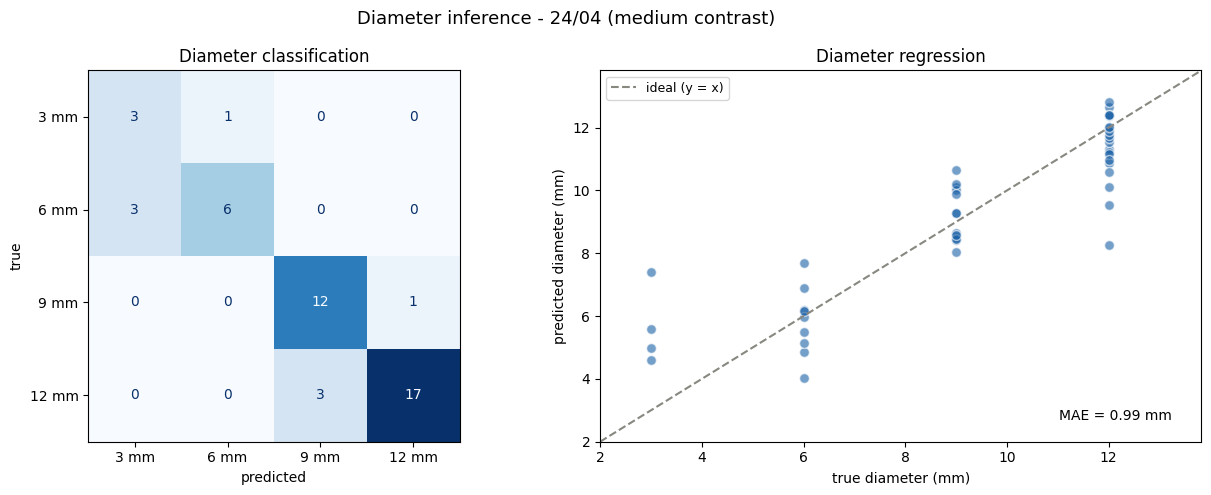

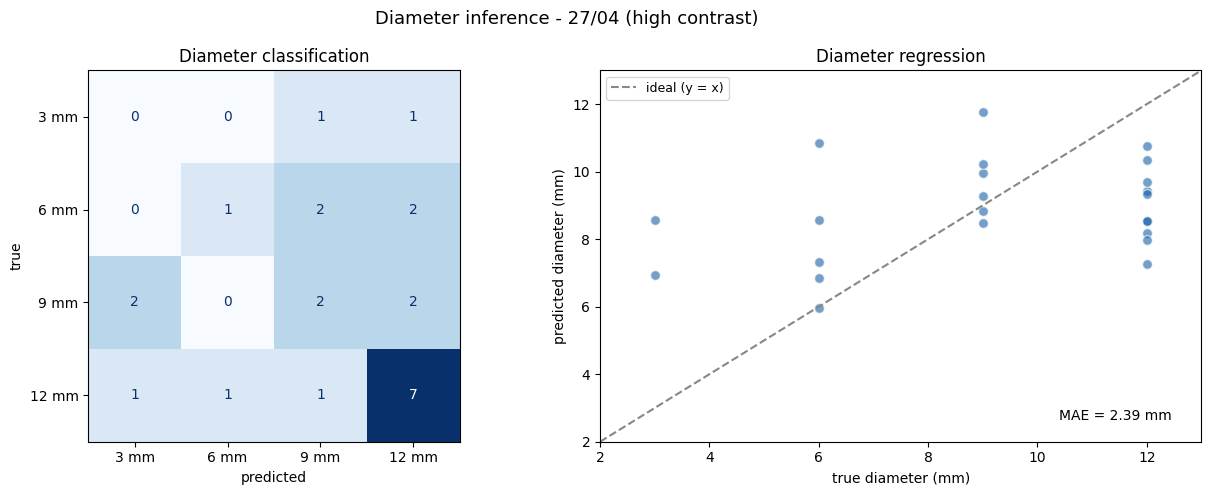

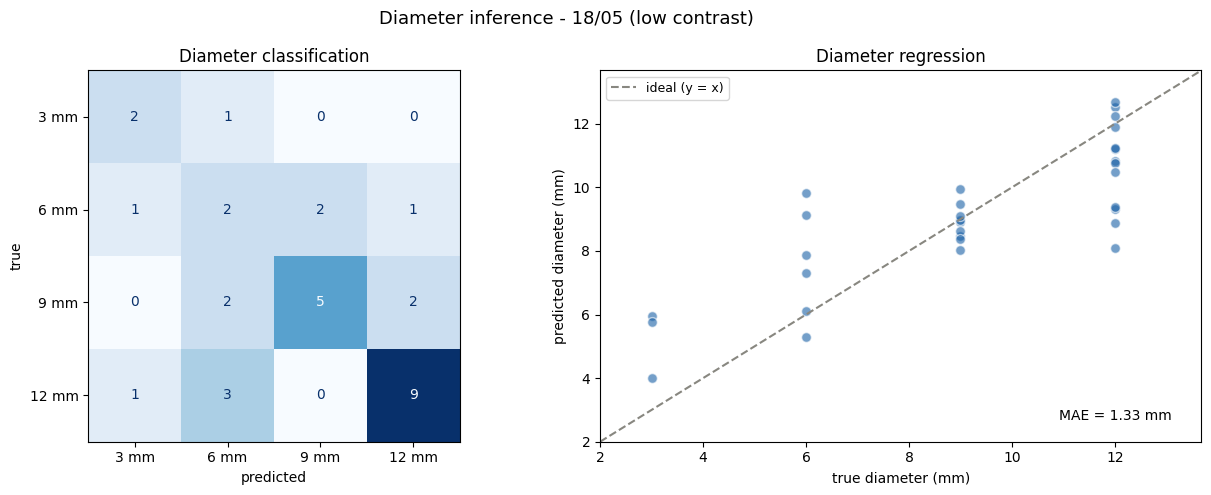

In [6]:
# ====================================================================
# 5. FIGURE - DIAMETER: confusion matrix (left) vs regression (right)
# ====================================================================
# One row per phantom. Left: confusion matrix of the multi-class classifier
# (errors should cluster near the diagonal = adjacent diameters). Right:
# predicted vs true diameter for the regressor (points should follow y = x).

for phantom_name, result in diameter_results.items():

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    # --- confusion matrix ---
    labels = sorted(np.unique(result["y_class_true"]))
    cm = confusion_matrix(
        result["y_class_true"],
        result["y_class_pred"],
        labels=labels
    )
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=[f"{d} mm" for d in labels]
    )
    disp.plot(
        ax=axes[0],
        values_format="d",
        colorbar=False,
        cmap="Blues"
    )
    axes[0].set_title("Diameter classification")
    axes[0].set_xlabel("predicted")
    axes[0].set_ylabel("true")

    # --- regression scatter ---
    true_r = result["y_reg_true"]
    pred_r = result["y_reg_pred"]

    axes[1].scatter(
        true_r, pred_r,
        c="#185FA5", alpha=0.6, edgecolor="white", s=50
    )

    lims = [min(true_r.min(), pred_r.min()) - 1,
            max(true_r.max(), pred_r.max()) + 1]
    axes[1].plot(lims, lims, "--", color="#888780", label="ideal (y = x)")

    axes[1].set_xlim(lims)
    axes[1].set_ylim(lims)
    axes[1].set_xlabel("true diameter (mm)")
    axes[1].set_ylabel("predicted diameter (mm)")
    axes[1].set_title("Diameter regression")
    axes[1].legend(loc="upper left", fontsize=9)

    mae = mean_absolute_error(true_r, pred_r)
    axes[1].text(
        0.95, 0.05, f"MAE = {mae:.2f} mm",
        transform=axes[1].transAxes, ha="right", va="bottom", fontsize=10
    )

    fig.suptitle(f"Diameter inference - {phantom_name}", fontsize=13)
    fig.tight_layout()

    safe = phantom_name.split()[0].replace("/", "-")
    fig.savefig(f"diameter_{safe}.png", dpi=200, bbox_inches="tight")
    plt.show()

**Position.** Each inclusion centre is estimated as the (rate-weighted) centroid of its hard points and compared with the ground-truth geometry.

In [7]:
# ====================================================================
# 6. POSITION - LOCALIZE THE INCLUSION CENTRES
# ====================================================================
# The centre of each inclusion is estimated as the centroid of the hard points
# assigned to that inclusion (optionally weighted by the response strength).
# The estimated centres are compared with the ground-truth geometry.
#
# GROUND TRUTH. If a phantom-geometry file is available, load the true sphere
# centres here and put them in `ground_truth_centres[phantom_name]` as a list of
# dicts {diameter, x, y}. Otherwise the centres are derived from the labeled data
# itself (centroid of the true-hard points of each inclusion), which lets the
# pipeline run end to end; replace with the real geometry when available.

def estimateInclusionCentres(hard, weight_by_rate=True):
    """
    Returns a table with one row per inclusion: estimated centre (x, y),
    dominant diameter, number of points and spatial extent.
    """

    rows = []

    for inc_id, sub in hard.groupby("inclusion_id"):

        if inc_id == -1:   # DBSCAN noise
            continue

        if weight_by_rate and sub["FR_loading_Hz"].notna().any():
            w = sub["FR_loading_Hz"].fillna(sub["FR_loading_Hz"].median()).to_numpy()
            w = np.clip(w, 1e-6, None)
        else:
            w = np.ones(len(sub))

        cx = np.average(sub["x"], weights=w)
        cy = np.average(sub["y"], weights=w)

        extent = np.sqrt(
            (sub["x"].max() - sub["x"].min()) ** 2
            + (sub["y"].max() - sub["y"].min()) ** 2
        )

        rows.append({
            "inclusion_id": inc_id,
            "diameter": sub["diameter"].mode().iloc[0],
            "x_est": cx,
            "y_est": cy,
            "n_points": len(sub),
            "extent": extent,
        })

    return pd.DataFrame(rows)


def deriveGroundTruthCentres(hard):
    """
    Ground-truth centres derived from the labeled data: unweighted centroid of
    the true-hard points of each inclusion. Replace with the real phantom
    geometry when the geometry file is available.
    """

    rows = []
    for inc_id, sub in hard.groupby("inclusion_id"):
        if inc_id == -1:
            continue
        rows.append({
            "inclusion_id": inc_id,
            "diameter": sub["diameter"].mode().iloc[0],
            "x": sub["x"].mean(),
            "y": sub["y"].mean(),
        })
    return pd.DataFrame(rows)


# Optional real geometry goes here, keyed by phantom name; leave empty to derive.
ground_truth_centres = {}


localization_results = {}

for phantom_name, hard in hard_tables.items():

    estimated = estimateInclusionCentres(hard)

    if phantom_name in ground_truth_centres:
        truth = ground_truth_centres[phantom_name]
    else:
        truth = deriveGroundTruthCentres(hard)

    # match estimated and true centres by inclusion_id
    merged = estimated.merge(
        truth[["inclusion_id", "x", "y"]],
        on="inclusion_id",
        suffixes=("", "_true")
    )


    merged["error_mm"] = np.sqrt(
        (merged["x_est"] - merged["x"]) ** 2
        + (merged["y_est"] - merged["y"]) ** 2
    ) * UM_TO_MM

    localization_results[phantom_name] = merged

    print(f"\n=== POSITION - {phantom_name} ===")
    print(
        merged[["inclusion_id", "diameter", "x_est", "y_est", "error_mm"]]
        .to_string(index=False)
    )
    print(f"  mean localization error: {merged['error_mm'].mean():.3f} mm")


=== POSITION - 24/04 (medium contrast) ===
 inclusion_id  diameter         x_est        y_est  error_mm
            0       3.0   1197.062778 -4804.064359  0.005015
            1       6.0  -1513.566901 -5293.948995  0.005625
            2       9.0  -8066.437643 -5209.064065  0.010303
            3      12.0 -11581.327064 -5244.834662  0.021868
  mean localization error: 0.011 mm

=== POSITION - 27/04 (high contrast) ===
 inclusion_id  diameter         x_est        y_est  error_mm
            0       3.0  11583.372175 -4016.627825  0.023515
            1       6.0   9599.735009 -4250.897474  0.010901
            2       9.0  -1965.717695 -4400.000000  0.034282
            3      12.0 -10181.207638 -3766.953230  0.022318
  mean localization error: 0.023 mm

=== POSITION - 18/05 (low contrast) ===
 inclusion_id  diameter        x_est        y_est  error_mm
            0       3.0 -7465.906933 -6800.046044  0.000761
            1       6.0 -3737.875627 -7064.073224  0.005231
           

**Figure — reconstructed map.** The phantom grid with hard points coloured by diameter and the estimated inclusion centres marked. This is the slide that shows the predicted layout against the ground truth.

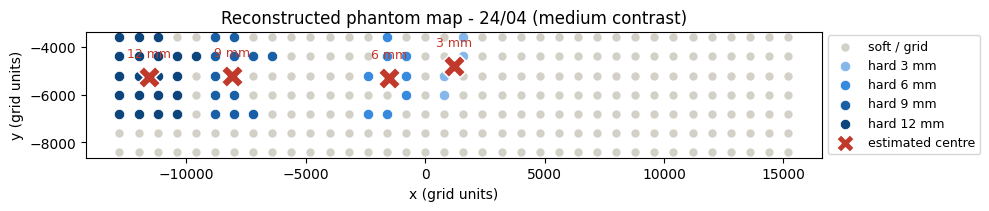

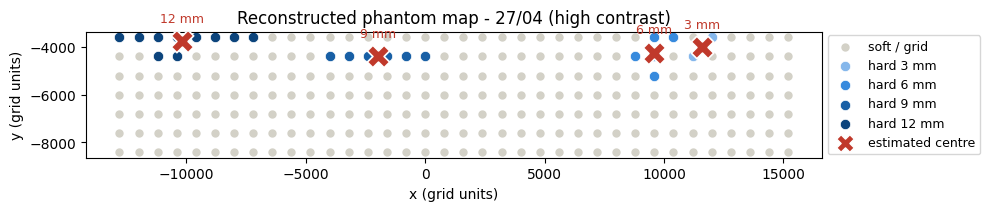

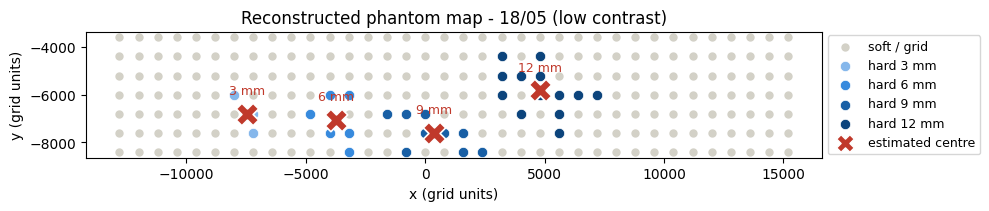

In [8]:
# ====================================================================
# 7. FIGURE - RECONSTRUCTED MAP: predicted vs ground truth
# ====================================================================
# The phantom map: all indented points in light grey, true-hard points coloured
# by diameter, the estimated inclusion centres marked with a cross, and the
# inclusion size suggested by the marker size. This is the slide that shows the
# system reconstructing the phantom.

diameter_color = {
    3.0:  "#85B7EB",
    6.0:  "#378ADD",
    9.0:  "#185FA5",
    12.0: "#0C447C",
}

for phantom_name in feature_tables:

    table = feature_tables[phantom_name]
    hard = hard_tables[phantom_name]
    estimated = estimateInclusionCentres(hard)

    fig, ax = plt.subplots(figsize=(10, 6))

    # all points (grid)
    ax.scatter(
        table["x"], table["y"],
        c="#D3D1C7", s=25, label="soft / grid"
    )

    # true-hard points, coloured by diameter
    for diam, color in diameter_color.items():
        sub = hard[hard["diameter"] == diam]
        if len(sub) == 0:
            continue
        ax.scatter(
            sub["x"], sub["y"],
            c=color, s=55, edgecolor="white", linewidth=0.5,
            label=f"hard {diam:.0f} mm"
        )

    # estimated centres
    for _, row in estimated.iterrows():
        ax.scatter(
            row["x_est"], row["y_est"],
            marker="X", s=260,
            c="#C0392B", edgecolor="white", linewidth=1.2,
            zorder=5
        )
        ax.annotate(
            f"{row['diameter']:.0f} mm",
            (row["x_est"], row["y_est"]),
            textcoords="offset points", xytext=(0, 14),
            ha="center", fontsize=9, color="#C0392B"
        )

    ax.scatter([], [], marker="X", s=160, c="#C0392B",
               edgecolor="white", label="estimated centre")

    ax.set_xlabel("x (grid units)")
    ax.set_ylabel("y (grid units)")
    ax.set_title(f"Reconstructed phantom map - {phantom_name}")
    ax.legend(loc="center left", bbox_to_anchor=(1.0, 0.5), fontsize=9)
    ax.set_aspect("equal", adjustable="box")

    fig.tight_layout()

    safe = phantom_name.split()[0].replace("/", "-")
    fig.savefig(f"phantom_map_{safe}.png", dpi=200, bbox_inches="tight")
    plt.show()

In [9]:
# ====================================================================
# 8. SAVE RESULTS
# ====================================================================
# Collect the diameter and position metrics into a single summary table and
# save it, together with all generated figures, under:
#     Results/diameter_decoding_results/
# ====================================================================

from pathlib import Path

results_root = Path(os.getcwd()) / "Results" / "diameter_decoding_results"
results_root.mkdir(parents=True, exist_ok=True)

# --------------------------------------------------------------------
# 1. Build the summary table (one row per phantom)
# --------------------------------------------------------------------

summary_rows = []

for phantom_name, result in diameter_results.items():

    # classification (point-level, optimistic)
    bal_acc = balanced_accuracy_score(result["y_class_true"], result["y_class_pred"])
    mi = mutual_info_score(result["y_class_true"], result["y_class_pred"])

    # regression, point-level (optimistic)
    mae_pt = mean_absolute_error(result["y_reg_true"], result["y_reg_pred"])
    r2_pt = r2_score(result["y_reg_true"], result["y_reg_pred"])

    # regression, leave-one-inclusion-out (honest)
    mae_inc = mean_absolute_error(result["y_reg_true"], result["y_reg_pred_inclusion"])

    # position: mean localization error
    if phantom_name in localization_results:
        mean_loc_error = localization_results[phantom_name]["error_mm"].mean()
    else:
        mean_loc_error = np.nan

    summary_rows.append({
        "phantom": phantom_name,
        "n_inclusions": result["n_inclusions"],
        "class_balanced_acc": bal_acc,
        "class_mutual_info_bits": mi,
        "reg_MAE_point_mm": mae_pt,
        "reg_R2_point": r2_pt,
        "reg_MAE_inclusion_mm": mae_inc,
        "mean_localization_error_mm": mean_loc_error,
    })

summary_table = pd.DataFrame(summary_rows)

summary_csv_path = results_root / "diameter_position_summary.csv"
summary_table.to_csv(summary_csv_path, sep=";", index=False)

print("Summary table saved to:", summary_csv_path)
print(summary_table.to_string(index=False))

# --------------------------------------------------------------------
# 2. Save the per-inclusion localization tables (full detail per phantom)
# --------------------------------------------------------------------

for phantom_name, merged in localization_results.items():
    safe = phantom_name.split()[0].replace("/", "-")
    merged.to_csv(
        results_root / f"localization_{safe}.csv",
        sep=";",
        index=False
    )

# --------------------------------------------------------------------
# 3. Re-generate and save the figures into the results folder
# --------------------------------------------------------------------

# --- 3a. Diameter figures (confusion matrix + regression scatter) ---
for phantom_name, result in diameter_results.items():

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    labels = sorted(np.unique(result["y_class_true"]))
    cm = confusion_matrix(result["y_class_true"], result["y_class_pred"], labels=labels)
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=[f"{d} mm" for d in labels]
    )
    disp.plot(ax=axes[0], values_format="d", colorbar=False, cmap="Blues")
    axes[0].set_title("Diameter classification")
    axes[0].set_xlabel("predicted")
    axes[0].set_ylabel("true")

    true_r = result["y_reg_true"]
    pred_r = result["y_reg_pred"]

    axes[1].scatter(true_r, pred_r, c="#185FA5", alpha=0.6, edgecolor="white", s=50)
    lims = [min(true_r.min(), pred_r.min()) - 1, max(true_r.max(), pred_r.max()) + 1]
    axes[1].plot(lims, lims, "--", color="#888780", label="ideal (y = x)")
    axes[1].set_xlim(lims)
    axes[1].set_ylim(lims)
    axes[1].set_xlabel("true diameter (mm)")
    axes[1].set_ylabel("predicted diameter (mm)")
    axes[1].set_title("Diameter regression")
    axes[1].legend(loc="upper left", fontsize=9)

    mae = mean_absolute_error(true_r, pred_r)
    axes[1].text(0.95, 0.05, f"MAE = {mae:.2f} mm",
                 transform=axes[1].transAxes, ha="right", va="bottom", fontsize=10)

    fig.suptitle(f"Diameter inference - {phantom_name}", fontsize=13)
    fig.tight_layout()

    safe = phantom_name.split()[0].replace("/", "-")
    fig.savefig(results_root / f"diameter_{safe}.png", dpi=200, bbox_inches="tight")
    plt.close(fig)

# --- 3b. Reconstructed phantom maps ---
diameter_color = {3.0: "#85B7EB", 6.0: "#378ADD", 9.0: "#185FA5", 12.0: "#0C447C"}

for phantom_name in feature_tables:

    table = feature_tables[phantom_name]
    hard = hard_tables[phantom_name]
    estimated = estimateInclusionCentres(hard)

    fig, ax = plt.subplots(figsize=(10, 6))

    ax.scatter(table["x"], table["y"], c="#D3D1C7", s=25, label="soft / grid")

    for diam, color in diameter_color.items():
        sub = hard[hard["diameter"] == diam]
        if len(sub) == 0:
            continue
        ax.scatter(sub["x"], sub["y"], c=color, s=55, edgecolor="white",
                   linewidth=0.5, label=f"hard {diam:.0f} mm")

    for _, row in estimated.iterrows():
        ax.scatter(row["x_est"], row["y_est"], marker="X", s=260,
                   c="#C0392B", edgecolor="white", linewidth=1.2, zorder=5)
        ax.annotate(f"{row['diameter']:.0f} mm", (row["x_est"], row["y_est"]),
                    textcoords="offset points", xytext=(0, 14),
                    ha="center", fontsize=9, color="#C0392B")

    ax.scatter([], [], marker="X", s=160, c="#C0392B",
               edgecolor="white", label="estimated centre")

    ax.set_xlabel("x (grid units)")
    ax.set_ylabel("y (grid units)")
    ax.set_title(f"Reconstructed phantom map - {phantom_name}")
    ax.legend(loc="center left", bbox_to_anchor=(1.0, 0.5), fontsize=9)
    ax.set_aspect("equal", adjustable="box")
    fig.tight_layout()

    safe = phantom_name.split()[0].replace("/", "-")
    fig.savefig(results_root / f"phantom_map_{safe}.png", dpi=200, bbox_inches="tight")
    plt.close(fig)

print(f"\nAll figures and tables saved in: {results_root}")

Summary table saved to: Results\diameter_decoding_results\diameter_position_summary.csv
                phantom  n_inclusions  class_balanced_acc  class_mutual_info_bits  reg_MAE_point_mm  reg_R2_point  reg_MAE_inclusion_mm  mean_localization_error_mm
24/04 (medium contrast)             4            0.797436                0.850881          0.989674      0.792559              2.693398                    0.010703
  27/04 (high contrast)             4            0.308333                0.182946          2.392576      0.079160              3.257544                    0.022754
   18/05 (low contrast)             4            0.561966                0.377949          1.327964      0.653968              3.221284                    0.003425

All figures and tables saved in: Results\diameter_decoding_results
